# RetailLens AI: Exploratory Data Analysis

This notebook describes the cleaned transaction line items and the daily net recorded revenue series. All reported values are calculated from `data/processed/cleaned_transactions.csv` and `data/processed/daily_revenue.csv`. Negative quantities and cancellation records remain in the data; revenue means `Quantity × UnitPrice`, not profit. Revenue and quantity rankings are reported separately. Country analysis describes the invoice customer-country field, not store regions.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data/processed/cleaned_transactions.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
TRANSACTION_PATH = PROJECT_ROOT / "data/processed/cleaned_transactions.csv"
DAILY_PATH = PROJECT_ROOT / "data/processed/daily_revenue.csv"

transactions = pd.read_csv(TRANSACTION_PATH, parse_dates=["InvoiceDate", "Date"])
daily = pd.read_csv(DAILY_PATH, parse_dates=["Date"])

# Matplotlib and Seaborn are used for all figures. Keep the numeric analysis
# runnable where those optional visualization dependencies are unavailable.
try:
    import matplotlib.pyplot as plt
    import seaborn as sns
    sns.set_theme(style="whitegrid", context="notebook")
    PLOTTING_AVAILABLE = True
except ImportError as error:
    plt = None
    sns = None
    PLOTTING_AVAILABLE = False
    print(f"Plots unavailable in this environment: {error}")

print(f"Loaded transaction rows: {len(transactions):,}; daily rows: {len(daily):,}")
print(f"Date range: {daily['Date'].min().date()} to {daily['Date'].max().date()}")


Loaded transaction rows: 536,639; daily rows: 305
Date range: 2010-12-01 to 2011-12-09


## A. Dataset overview

The transaction file contains line-level records; daily revenue contains one aggregate per date with recorded transactions.

In [2]:
print("TRANSACTION DATASET")
print("Shape:", transactions.shape)
print("Columns:", transactions.columns.tolist())
print("Data types:\n", transactions.dtypes.to_string())
print("Missing values by column:\n", transactions.isna().sum().to_string())
print("Descriptive statistics (numeric columns):\n", transactions.describe().to_string())
print("\nDAILY REVENUE DATASET")
print("Shape:", daily.shape)
print("Columns:", daily.columns.tolist())
print("Data types:\n", daily.dtypes.to_string())
print("Missing values by column:\n", daily.isna().sum().to_string())
print("Descriptive statistics:\n", daily.describe().to_string())


TRANSACTION DATASET
Shape: (536639, 11)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'IsCancellation', 'Revenue', 'Date']
Data types:
 InvoiceNo                    str
StockCode                    str
Description                  str
Quantity                   int64
InvoiceDate       datetime64[us]
UnitPrice                float64
CustomerID               float64
Country                      str
IsCancellation              bool
Revenue                  float64
Date              datetime64[us]
Missing values by column:
 InvoiceNo              0
StockCode              0
Description         1454
Quantity               0
InvoiceDate            0
UnitPrice              0
CustomerID        135035
Country                0
IsCancellation         0
Revenue                0
Date                   0
Descriptive statistics (numeric columns):
             Quantity                 InvoiceDate      UnitPrice     CustomerID        

## B. Daily revenue analysis

The time plot shows recorded daily totals only; dates with no retained records are absent rather than represented as zero. The histogram describes the distribution across those observed dates.

Daily revenue statistics:
minimum daily revenue: -1,570.43
maximum daily revenue: 111,958.62
positive-revenue days: 304
negative-revenue days: 1
zero-revenue days: 0


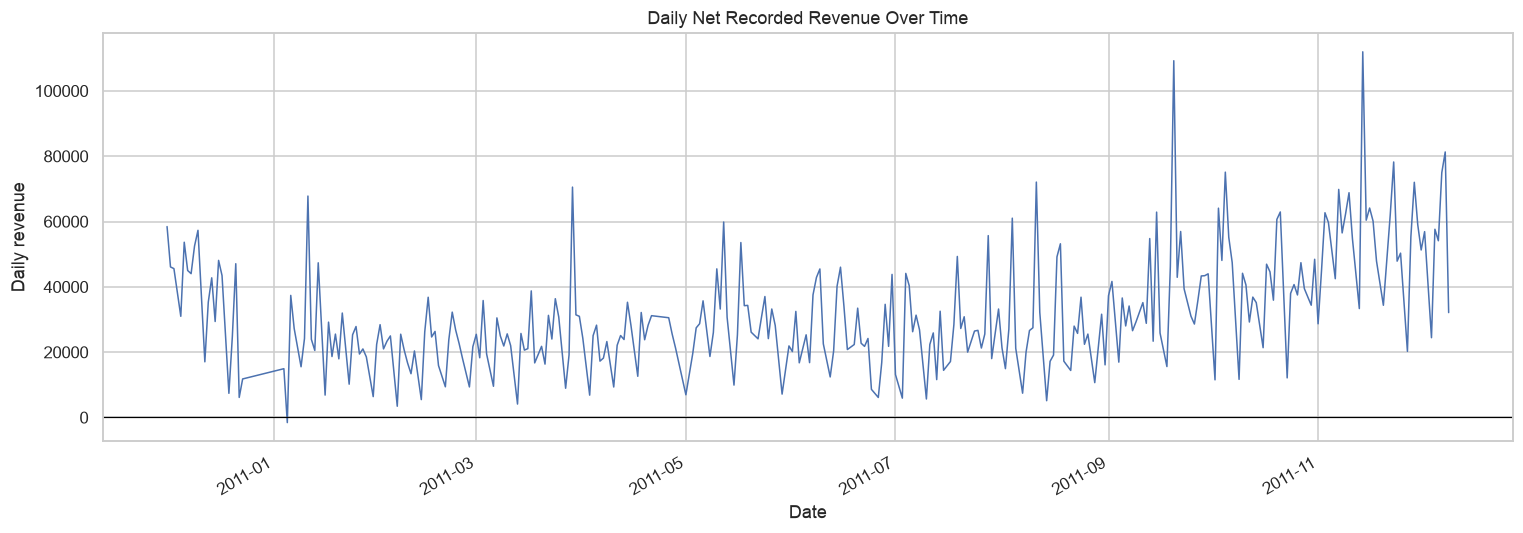

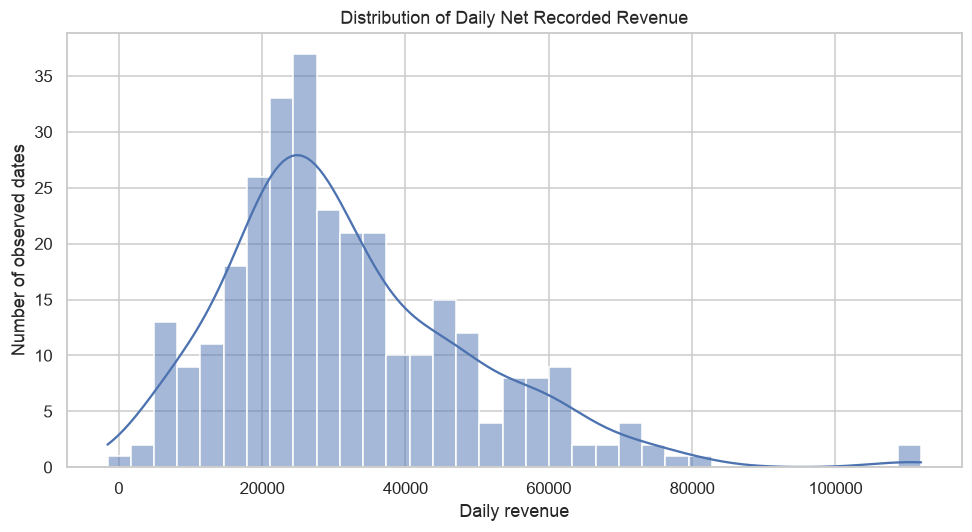

In [3]:
daily = daily.sort_values("Date").reset_index(drop=True)
revenue_counts = {
    "minimum daily revenue": daily["DailyRevenue"].min(),
    "maximum daily revenue": daily["DailyRevenue"].max(),
    "positive-revenue days": int((daily["DailyRevenue"] > 0).sum()),
    "negative-revenue days": int((daily["DailyRevenue"] < 0).sum()),
    "zero-revenue days": int((daily["DailyRevenue"] == 0).sum()),
}
print("Daily revenue statistics:")
for name, value in revenue_counts.items():
    print(f"{name}: {value:,.2f}" if isinstance(value, (float, np.floating)) else f"{name}: {value:,}")

if PLOTTING_AVAILABLE:
    fig, ax = plt.subplots(figsize=(14, 5))
    sns.lineplot(data=daily, x="Date", y="DailyRevenue", ax=ax, linewidth=1)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title="Daily Net Recorded Revenue Over Time", xlabel="Date", ylabel="Daily revenue")
    fig.autofmt_xdate(); fig.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(9, 5))
    sns.histplot(data=daily, x="DailyRevenue", bins=35, kde=True, ax=ax)
    ax.set(title="Distribution of Daily Net Recorded Revenue", xlabel="Daily revenue", ylabel="Number of observed dates")
    fig.tight_layout(); plt.show()
else:
    print("Charts in this section require Matplotlib and Seaborn.")


**What these charts show.** Of the 305 observed dates, 304 have positive revenue and one has negative revenue (2011-01-05, -1,570.43); none is exactly zero. The time plot shows pronounced day-to-day variation, while the histogram shows a concentrated lower range with a small number of large daily values. These plots describe recorded daily net revenue only.


## C. Time-based analysis

Weekday summaries are calculated across dates present in the daily file. Monthly revenue uses daily totals; monthly transaction volume counts retained transaction line items. Unique-customer counts exclude missing `CustomerID` values.

Revenue by day of week (only dates present in daily data):
 DayOfWeek  observed_days  total_revenue  mean_daily_revenue
   Monday           47.0    1584895.301        33721.176617
  Tuesday           52.0    1965703.611        37801.992519
Wednesday           53.0    1730088.430        32643.177925
 Thursday           53.0    2108701.530        39786.821321
   Friday           50.0    1560082.741        31201.654820
 Saturday            NaN            NaN                 NaN
   Sunday           50.0     798659.461        15973.189220

Monthly revenue, transaction line-item volume, and unique customers:
   Month  DailyRevenue  transaction_line_items  unique_customers
2010-12    746723.610                   41981               948
2011-01    558448.560                   34900               783
2011-02    497026.410                   27479               798
2011-03    682013.980                   36439              1020
2011-04    492367.841                   29701               899
2011-

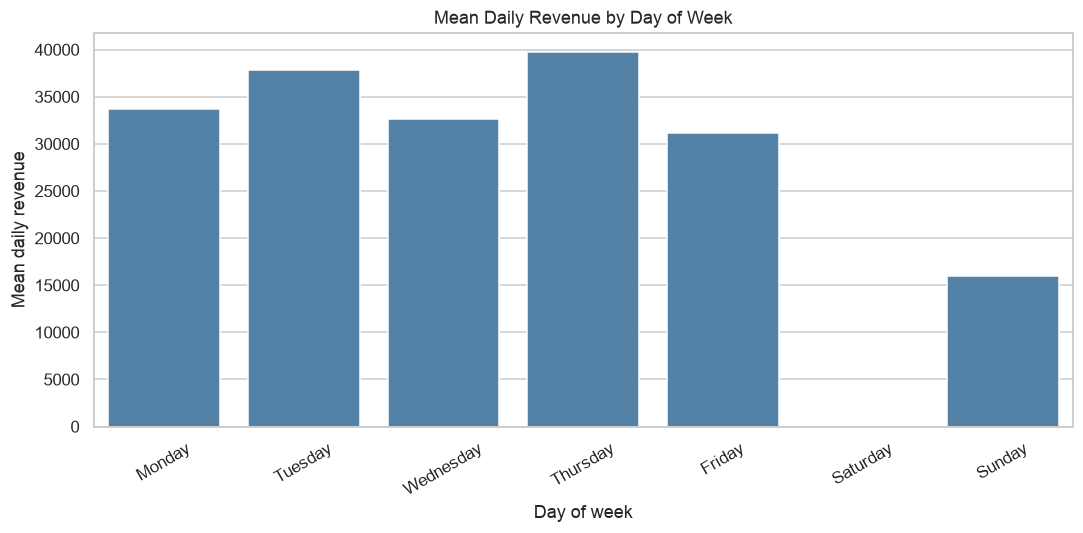

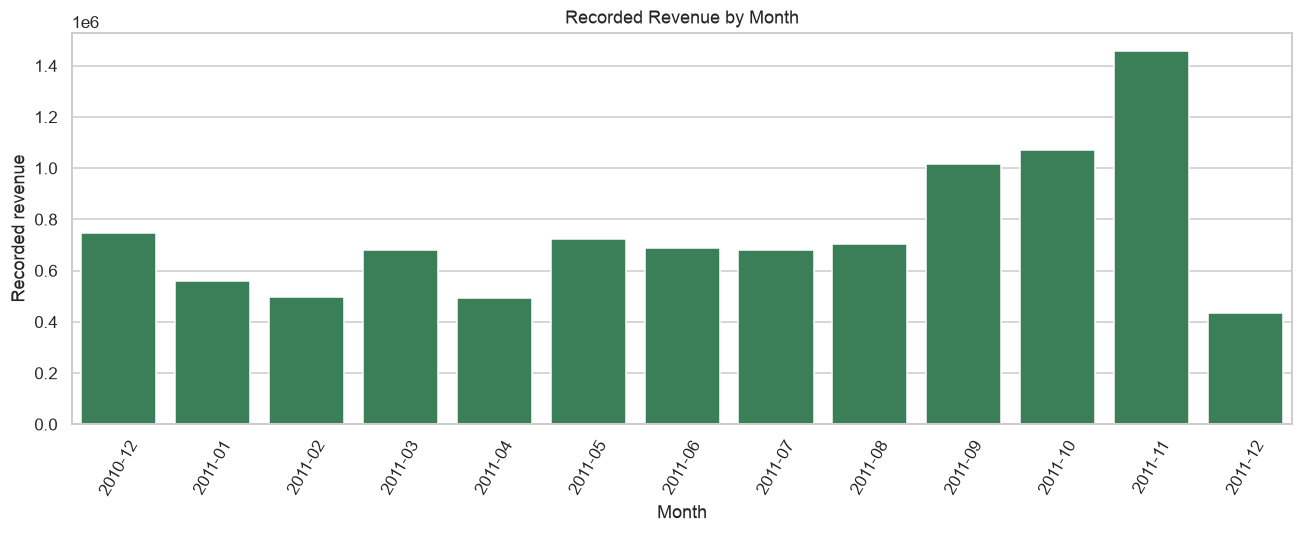

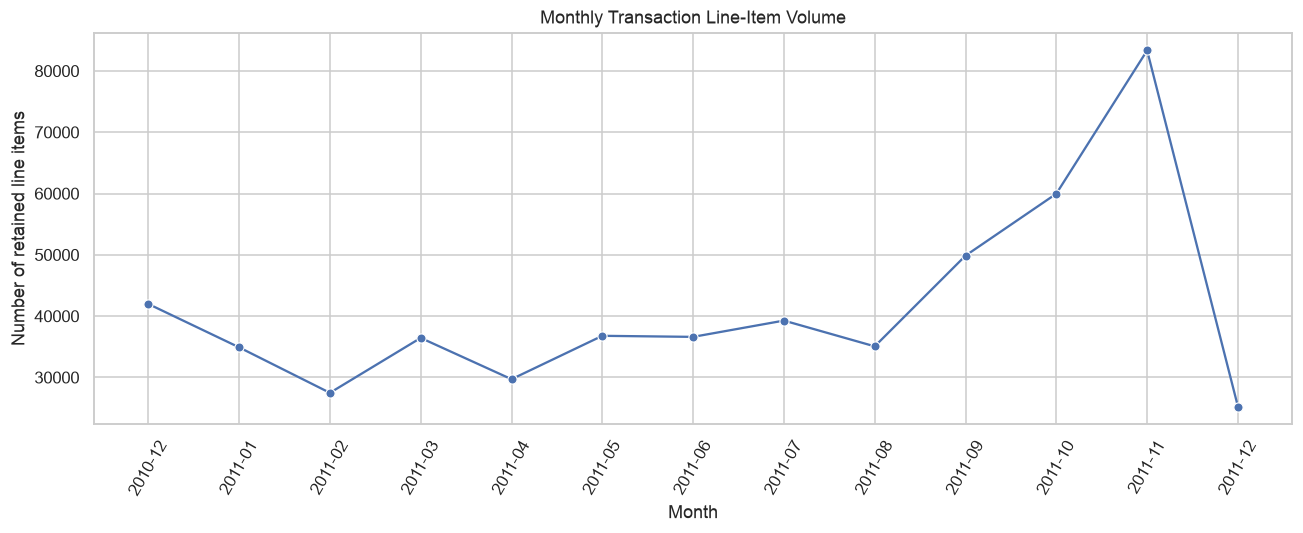

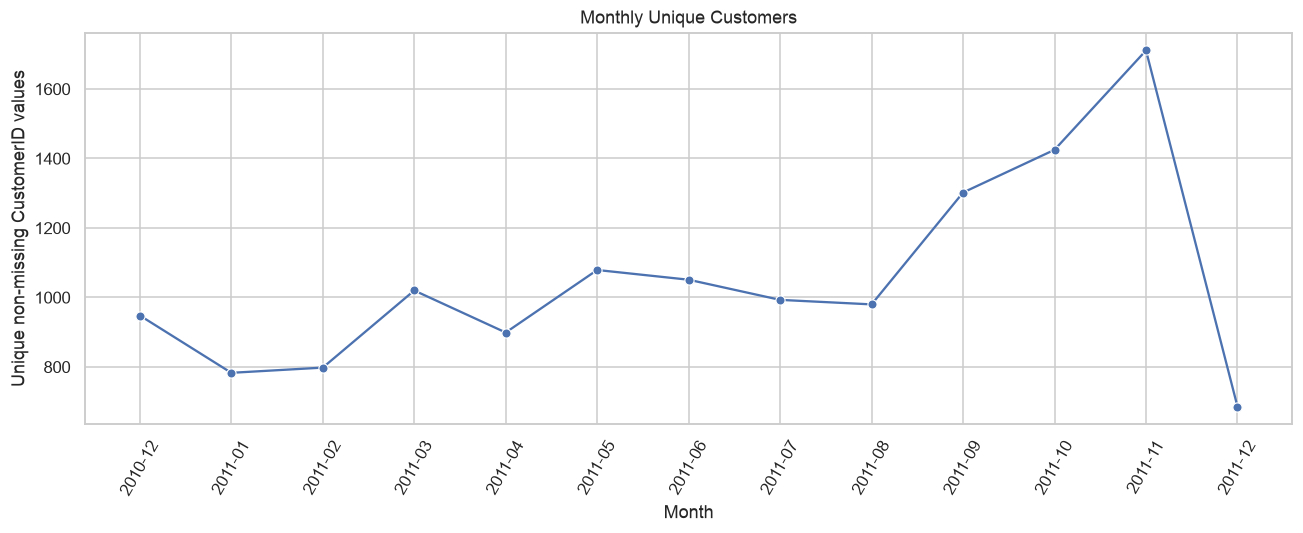

In [4]:
daily["DayOfWeek"] = daily["Date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = (daily.groupby("DayOfWeek")["DailyRevenue"]
           .agg(observed_days="count", total_revenue="sum", mean_daily_revenue="mean")
           .reindex(weekday_order).reset_index())
print("Revenue by day of week (only dates present in daily data):\n", weekday.to_string(index=False))

transactions["Month"] = transactions["InvoiceDate"].dt.to_period("M").astype(str)
monthly_revenue = daily.assign(Month=daily["Date"].dt.to_period("M").astype(str)).groupby("Month", as_index=False)["DailyRevenue"].sum()
monthly_lines = transactions.groupby("Month").size().rename("transaction_line_items")
monthly_customers = transactions.groupby("Month")["CustomerID"].nunique().rename("unique_customers")
monthly = (monthly_revenue.set_index("Month")
           .join(monthly_lines).join(monthly_customers).reset_index())
print("\nMonthly revenue, transaction line-item volume, and unique customers:\n", monthly.to_string(index=False))

if PLOTTING_AVAILABLE:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=weekday, x="DayOfWeek", y="mean_daily_revenue", order=weekday_order, color="steelblue", ax=ax)
    ax.set(title="Mean Daily Revenue by Day of Week", xlabel="Day of week", ylabel="Mean daily revenue")
    ax.tick_params(axis="x", rotation=30); fig.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.barplot(data=monthly, x="Month", y="DailyRevenue", color="seagreen", ax=ax)
    ax.set(title="Recorded Revenue by Month", xlabel="Month", ylabel="Recorded revenue")
    ax.tick_params(axis="x", rotation=60); fig.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.lineplot(data=monthly, x="Month", y="transaction_line_items", marker="o", ax=ax)
    ax.set(title="Monthly Transaction Line-Item Volume", xlabel="Month", ylabel="Number of retained line items")
    ax.tick_params(axis="x", rotation=60); fig.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    sns.lineplot(data=monthly, x="Month", y="unique_customers", marker="o", ax=ax)
    ax.set(title="Monthly Unique Customers", xlabel="Month", ylabel="Unique non-missing CustomerID values")
    ax.tick_params(axis="x", rotation=60); fig.tight_layout(); plt.show()
else:
    print("Charts in this section require Matplotlib and Seaborn.")


**What these charts show.** Mean revenue differs across observed weekdays: Thursday is highest (39,786.82) and Sunday lowest (15,973.19); there are no Saturday records in this file. Monthly totals rise to their largest observed value in November 2011 (1,456,145.80), line-item volume is also highest in November (83,343), and the unique-customer count peaks in November (1,711). December 2011 is partial, ending on December 9, so its total is not comparable to a full month. These summaries show variation, not a cause.


## D. Product analysis

Product revenue is net recorded revenue summed by stock code and description, including negative values. The quantity ranking uses net recorded quantity, which is a distinct measure and can include returns/corrections. Product categories are not present in the source and are not inferred.

Top products by recorded revenue:
 StockCode                        Description  RecordedRevenue
      DOT                     DOTCOM POSTAGE        206245.48
    22423           REGENCY CAKESTAND 3 TIER        164459.49
    47566                      PARTY BUNTING         98243.88
   85123A WHITE HANGING HEART T-LIGHT HOLDER         97659.94
   85099B            JUMBO BAG RED RETROSPOT         92175.79
    23084                 RABBIT NIGHT LIGHT         66661.63
     POST                            POSTAGE         66230.64
    22086    PAPER CHAIN KIT 50'S CHRISTMAS          63715.24
    84879      ASSORTED COLOUR BIRD ORNAMENT         58792.42
    79321                      CHILLI LIGHTS         53746.66

Top products by net recorded quantity (units):
 StockCode                        Description  NetRecordedQuantity
    84077  WORLD WAR 2 GLIDERS ASSTD DESIGNS                53751
   85099B            JUMBO BAG RED RETROSPOT                47260
    22197                     POPCOR

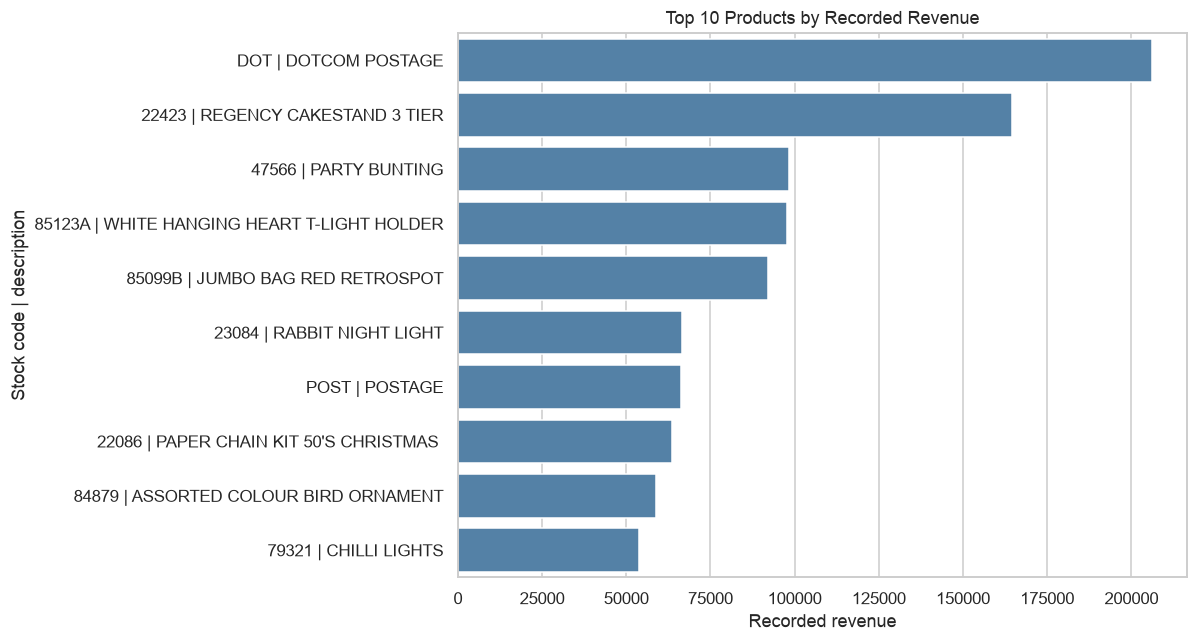

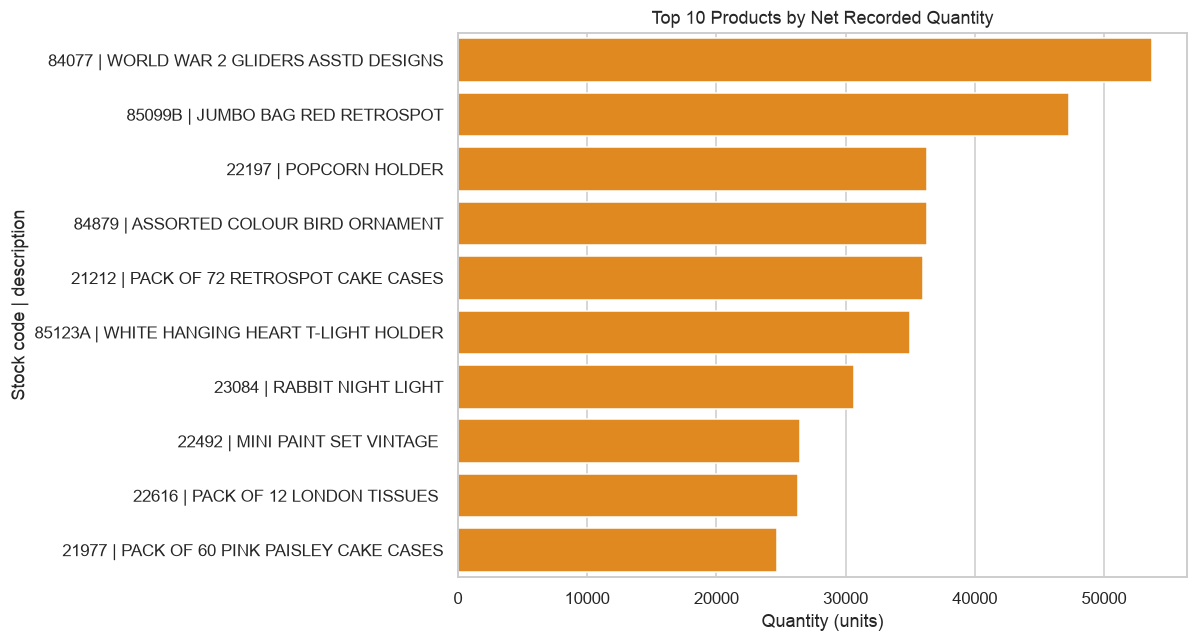

In [5]:
product_keys = ["StockCode", "Description"]
product_revenue = (transactions.groupby(product_keys, dropna=False)["Revenue"].sum()
                   .sort_values(ascending=False).head(10).rename("RecordedRevenue").reset_index())
product_quantity = (transactions.groupby(product_keys, dropna=False)["Quantity"].sum()
                    .sort_values(ascending=False).head(10).rename("NetRecordedQuantity").reset_index())
print("Top products by recorded revenue:\n", product_revenue.to_string(index=False))
print("\nTop products by net recorded quantity (units):\n", product_quantity.to_string(index=False))

if PLOTTING_AVAILABLE:
    rev_plot = product_revenue.assign(Product=product_revenue["StockCode"].astype(str) + " | " + product_revenue["Description"].fillna("(missing)"))
    qty_plot = product_quantity.assign(Product=product_quantity["StockCode"].astype(str) + " | " + product_quantity["Description"].fillna("(missing)"))
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.barplot(data=rev_plot, y="Product", x="RecordedRevenue", color="steelblue", ax=ax)
    ax.set(title="Top 10 Products by Recorded Revenue", xlabel="Recorded revenue", ylabel="Stock code | description")
    fig.tight_layout(); plt.show()
    fig, ax = plt.subplots(figsize=(11, 6))
    sns.barplot(data=qty_plot, y="Product", x="NetRecordedQuantity", color="darkorange", ax=ax)
    ax.set(title="Top 10 Products by Net Recorded Quantity", xlabel="Quantity (units)", ylabel="Stock code | description")
    fig.tight_layout(); plt.show()
else:
    print("Charts in this section require Matplotlib and Seaborn.")


**What these charts show.** The highest recorded-revenue item code is DOT / DOTCOM POSTAGE (206,245.48). The greatest net recorded quantity belongs to item code 84077 / WORLD WAR 2 GLIDERS ASSTD DESIGNS (53,751 units). The rankings differ because revenue and quantity measure different things.


## E. Geographic analysis

Country labels come from the invoice `Country` field and describe customer-country revenue and line-item quantity, not store-region performance.

Revenue and quantity by customer country (top 15 by revenue):
                       RecordedRevenue  TransactionQuantity
Country                                                   
United Kingdom            8189252.304              4250326
Netherlands                284661.540               200128
EIRE                       262993.380               142495
Germany                    221509.470               117341
France                     197317.110               110438
Australia                  137009.770                83643
Switzerland                 56363.050                30313
Spain                       54756.030                26817
Belgium                     40910.960                23152
Sweden                      36585.410                35632
Japan                       35340.620                25218
Norway                      35163.460                19247
Portugal                    29302.970                16153
Finland                     22326.740               

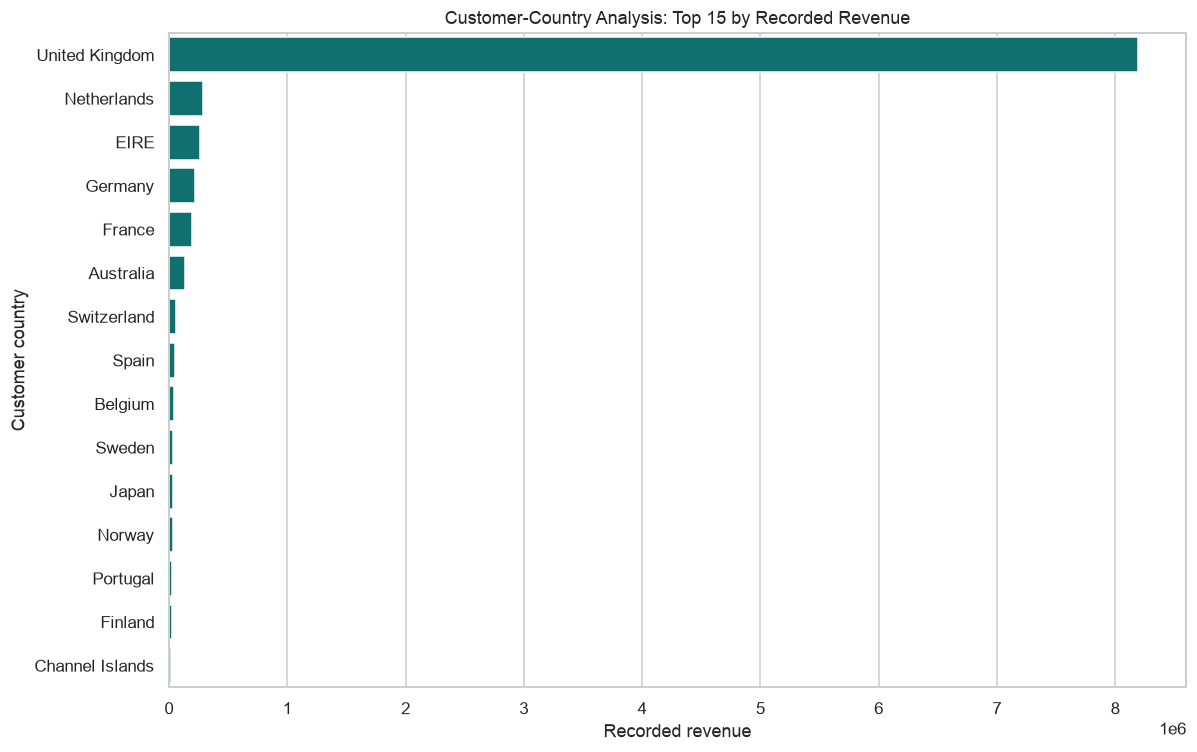

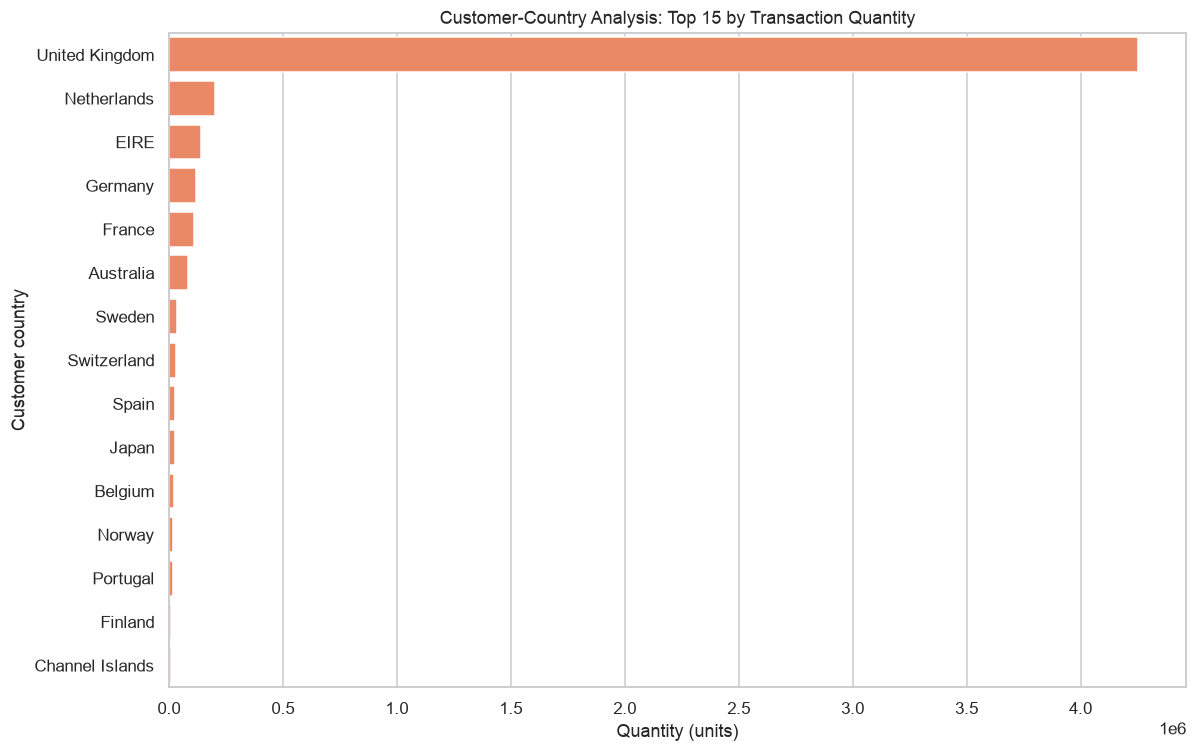

In [6]:
country = (transactions.groupby("Country", dropna=False)
           .agg(RecordedRevenue=("Revenue", "sum"), TransactionQuantity=("Quantity", "sum"))
           .sort_values("RecordedRevenue", ascending=False))
print("Revenue and quantity by customer country (top 15 by revenue):\n", country.to_string())

if PLOTTING_AVAILABLE:
    country_plot = country.head(15).reset_index()
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.barplot(data=country_plot, y="Country", x="RecordedRevenue", color="teal", ax=ax)
    ax.set(title="Customer-Country Analysis: Top 15 by Recorded Revenue", xlabel="Recorded revenue", ylabel="Customer country")
    fig.tight_layout(); plt.show()
    qty_country_plot = country.sort_values("TransactionQuantity", ascending=False).head(15).reset_index()
    fig, ax = plt.subplots(figsize=(11, 7))
    sns.barplot(data=qty_country_plot, y="Country", x="TransactionQuantity", color="coral", ax=ax)
    ax.set(title="Customer-Country Analysis: Top 15 by Transaction Quantity", xlabel="Quantity (units)", ylabel="Customer country")
    fig.tight_layout(); plt.show()
else:
    print("Charts in this section require Matplotlib and Seaborn.")


**What these charts show.** United Kingdom has the largest recorded revenue (8,189,252.30) and transaction quantity (4,250,326) among customer-country values. These are customer-country totals, not store-region totals.


## F. Customer analysis

Customer metrics use non-missing `CustomerID` values. Recorded revenue sums include returns/cancellations present in the cleaned data.

Unique customers with CustomerID: 4,372
Recorded revenue by customer (descriptive statistics):
 count      4372.000000
mean       1893.531433
std        8218.696204
min       -4287.630000
25%         291.795000
50%         644.070000
75%        1608.335000
max      279489.020000
Top 10 customers by recorded revenue:
 CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187322.17
14911.0    132458.73
12415.0    123725.45
14156.0    113214.59
17511.0     88125.38
16684.0     65892.08
13694.0     62690.54
15311.0     59284.19


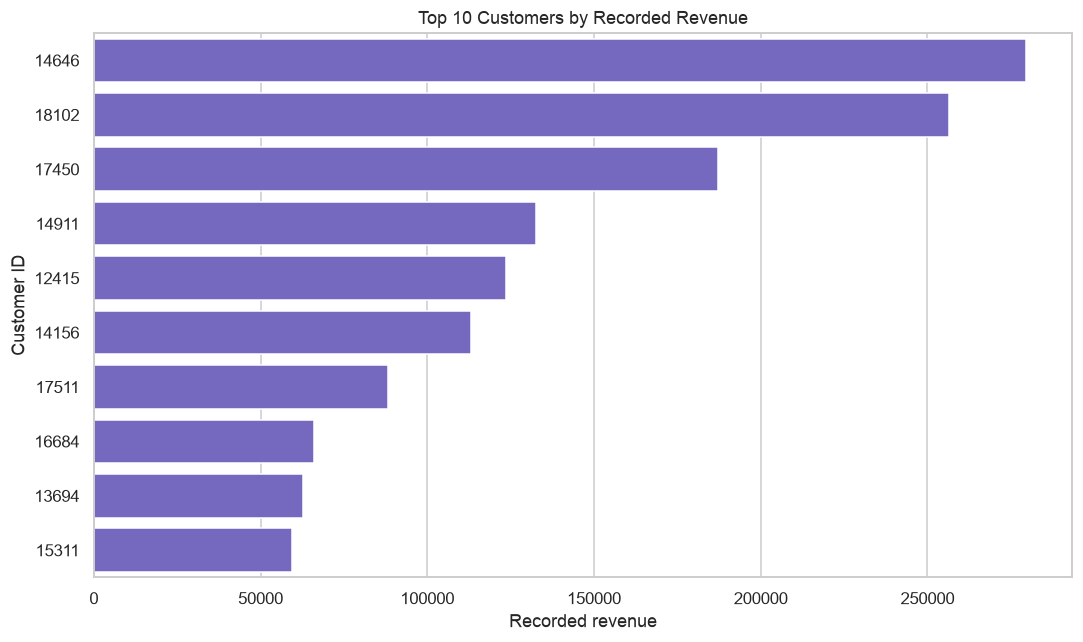

In [7]:
customer_rows = transactions.dropna(subset=["CustomerID"])
unique_customers = int(customer_rows["CustomerID"].nunique())
customer_revenue = customer_rows.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
print(f"Unique customers with CustomerID: {unique_customers:,}")
print("Recorded revenue by customer (descriptive statistics):\n", customer_revenue.describe().to_string())
print("Top 10 customers by recorded revenue:\n", customer_revenue.head(10).rename("RecordedRevenue").to_string())

if PLOTTING_AVAILABLE:
    top_customer = customer_revenue.head(10).rename("RecordedRevenue").reset_index()
    top_customer["CustomerID"] = top_customer["CustomerID"].astype("Int64").astype(str)
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=top_customer, y="CustomerID", x="RecordedRevenue", color="slateblue", ax=ax)
    ax.set(title="Top 10 Customers by Recorded Revenue", xlabel="Recorded revenue", ylabel="Customer ID")
    fig.tight_layout(); plt.show()
else:
    print("Chart in this section requires Matplotlib and Seaborn.")


**What this chart shows.** There are 4,372 identifiable customers. The highest summed recorded revenue among them is 279,489.02 (CustomerID 14646); customer totals vary widely, and rows without CustomerID are not included in these customer-level calculations.


## G. Data-quality observations

These checks describe the remaining cleaned data. Extreme values are flagged descriptively with quantiles and largest absolute transaction revenues; they are not removed or labeled as errors by this notebook.

Remaining missing values by column:
 InvoiceNo              0
StockCode              0
Description         1454
Quantity               0
InvoiceDate            0
UnitPrice              0
CustomerID        135035
Country                0
IsCancellation         0
Revenue                0
Date                   0
Month                  0
Rows with negative quantity: 10,587
Rows with zero UnitPrice: 2,510
Cancellation records (InvoiceNo prefix C): 9,251
Transaction-line revenue quantiles:
 0.00   -168469.6000
0.01        -6.6000
0.50         9.8700
0.95        59.4000
0.99       180.3746
1.00    168469.6000
10 transaction lines with greatest absolute recorded revenue:
 InvoiceNo StockCode         InvoiceDate  Quantity  UnitPrice    Revenue  IsCancellation
   581483     23843 2011-12-09 09:15:00     80995       2.08  168469.60           False
  C581484     23843 2011-12-09 09:27:00    -80995       2.08 -168469.60            True
   541431     23166 2011-01-18 10:01:00     74215       1.04  

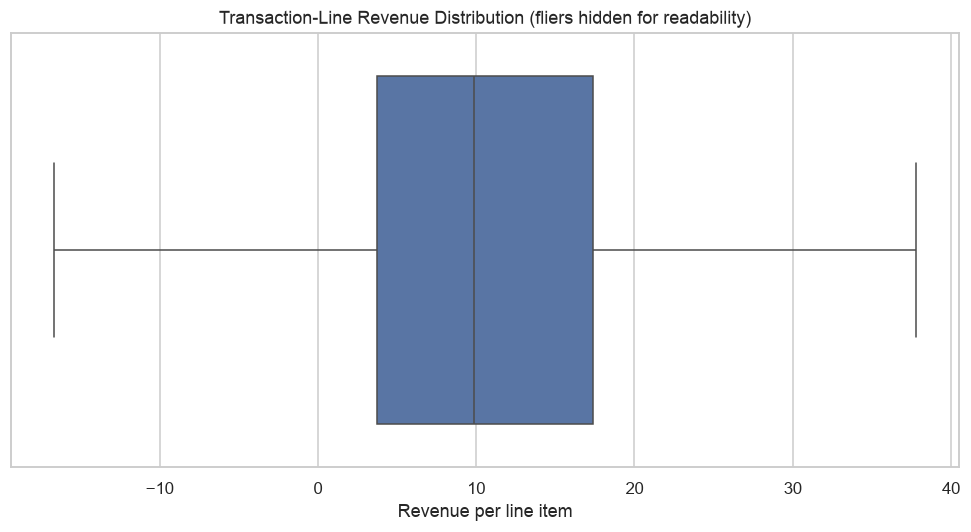

In [8]:
missing_values = transactions.isna().sum()
negative_quantity_rows = int((transactions["Quantity"] < 0).sum())
zero_price_rows = int((transactions["UnitPrice"] == 0).sum())
cancellation_rows = int(transactions["IsCancellation"].sum())
line_revenue_quantiles = transactions["Revenue"].quantile([0, .01, .50, .95, .99, 1])
most_extreme_lines = transactions.loc[transactions["Revenue"].abs().nlargest(10).index,
                                    ["InvoiceNo", "StockCode", "InvoiceDate", "Quantity", "UnitPrice", "Revenue", "IsCancellation"]]
calendar = pd.date_range(daily["Date"].min(), daily["Date"].max(), freq="D")
missing_dates = calendar.difference(daily["Date"])
print("Remaining missing values by column:\n", missing_values.to_string())
print(f"Rows with negative quantity: {negative_quantity_rows:,}")
print(f"Rows with zero UnitPrice: {zero_price_rows:,}")
print(f"Cancellation records (InvoiceNo prefix C): {cancellation_rows:,}")
print("Transaction-line revenue quantiles:\n", line_revenue_quantiles.to_string())
print("10 transaction lines with greatest absolute recorded revenue:\n", most_extreme_lines.to_string(index=False))
print(f"Missing calendar dates in daily file: {len(missing_dates):,} of {len(calendar):,} dates in full range")
print("First missing dates:", [d.date().isoformat() for d in missing_dates[:20]])

if PLOTTING_AVAILABLE:
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.boxplot(x=transactions["Revenue"], ax=ax, showfliers=False)
    ax.set(title="Transaction-Line Revenue Distribution (fliers hidden for readability)", xlabel="Revenue per line item")
    fig.tight_layout(); plt.show()
else:
    print("Chart in this section requires Matplotlib and Seaborn.")


**What these checks show.** Missing values remain in `CustomerID` (135,035 rows) and `Description` (1,454 rows). The cleaned records include 10,587 negative-quantity rows, 2,510 zero-price rows, and 9,251 cancellation-prefixed rows. The largest absolute line-item revenues include equal positive/negative pairs of 168,469.60 and 77,183.60. They are extreme recorded values worth preserving and reviewing, not automatically data errors. The transaction-level boxplot hides fliers so the central distribution remains readable; the quantiles and largest absolute values above show the tail range.


## Forecasting relevance

The checks below calculate weekday differences, month totals, daily spikes relative to the observed daily-revenue distribution, negative days, and dates absent from the daily file. Absent dates mean no retained dated transaction rows were aggregated for those calendar days; they are not automatically zero-revenue observations. Interpret weekday averages with that coverage limitation in mind.


In [9]:
weekday_means = weekday.set_index("DayOfWeek")["mean_daily_revenue"]
weekday_range = weekday_means.max() - weekday_means.min()
monthly_nonzero = monthly.loc[monthly["DailyRevenue"] != 0, "DailyRevenue"]
spike_threshold = daily["DailyRevenue"].quantile(0.99)
spikes = daily.loc[daily["DailyRevenue"] >= spike_threshold, ["Date", "DailyRevenue"]]
print(f"Weekday mean revenue range: {weekday_range:,.2f}")
print("Weekday mean revenue ranking (descriptive, observed dates):\n", weekday.sort_values("mean_daily_revenue", ascending=False).to_string(index=False))
print("Monthly revenue totals:\n", monthly[["Month", "DailyRevenue"]].to_string(index=False))
print(f"Daily revenue 99th percentile spike threshold: {spike_threshold:,.2f}")
print("Dates at or above that threshold:\n", spikes.to_string(index=False))
print(f"Negative-revenue days: {(daily['DailyRevenue'] < 0).sum():,}")
print(f"Missing calendar dates: {len(missing_dates):,}")


Weekday mean revenue range: 23,813.63
Weekday mean revenue ranking (descriptive, observed dates):
 DayOfWeek  observed_days  total_revenue  mean_daily_revenue
 Thursday           53.0    2108701.530        39786.821321
  Tuesday           52.0    1965703.611        37801.992519
   Monday           47.0    1584895.301        33721.176617
Wednesday           53.0    1730088.430        32643.177925
   Friday           50.0    1560082.741        31201.654820
   Sunday           50.0     798659.461        15973.189220
 Saturday            NaN            NaN                 NaN
Monthly revenue totals:
   Month  DailyRevenue
2010-12    746723.610
2011-01    558448.560
2011-02    497026.410
2011-03    682013.980
2011-04    492367.841
2011-05    722094.100
2011-06    689977.230
2011-07    680156.991
2011-08    703510.580
2011-09   1017596.682
2011-10   1069368.230
2011-11   1456145.800
2011-12    432701.060
Daily revenue 99th percentile spike threshold: 78,099.04
Dates at or above that threshol

## EDA Findings Relevant to Machine Learning

- **Patterns:** Across observed dates, Thursday has the highest mean daily revenue (39,786.82) and Sunday the lowest (15,973.19); Saturday has no recorded daily rows. Monthly recorded revenue is largest in November 2011 (1,456,145.80), and monthly retained line-item volume also peaks then (83,343). September through November totals are higher than the earlier full months shown. These patterns may reflect date coverage and are descriptive only.
- **Anomalies:** One daily total is negative (-1,570.43 on 2011-01-05); there are 69 calendar dates without a daily aggregate in the 374-day date span. The daily 99th percentile is 78,099.04, with the maximum 111,958.62 on 2011-11-14. Extreme transaction-line values include +168,469.60 and -168,469.60. Negative quantities, cancellations, zero-price rows, and missing customer IDs remain present.
- **Candidate features (conceptual only):** Calendar weekday and month, plus lagged or rolling summaries of prior daily net recorded revenue, could be considered later if calculated strictly from information available before each forecast date. No features are built here.
- **Potential risks:** Missing calendar dates must be distinguished from true zero revenue; blindly filling them changes the series definition. Returns/cancellations contribute to net recorded revenue. Extreme line items can materially affect daily totals. December is only observed through December 9.
- **Cautions:** Revenue is not profit. Country measures customer country, not store geography. Quantity and revenue are distinct. Customer-level analysis excludes rows without `CustomerID`. Weekday and monthly differences are descriptive associations; they do not explain causes or establish predictive value.
